# 1120 — IonSim check of the effective model used in 1113

**Question.** 1113 (and 1104) never put a laser in the Hamiltonian. The signal is the ideal drive `i(β/t_sig)(a† − a)` and the readout is the ideal, instantaneous unitary `P₊⊗D(iα) + P₋⊗D(−iα)`; 1104 used IonSim only to get η, Ω and `t_sig`. Does the QCRB change when the readout is a real bichromatic laser pulse simulated by IonSim?

**What this notebook compares**, all starting from the same post-signal motional state ρ(β), ∂ρ/∂β produced by the 1113 engine:

| Label | Readout model |
| --- | --- |
| **E0** | 1113 as is: instantaneous ideal SDF, `C = Tr[D(2iα)ρ]` |
| **E1** | ideal SDF Hamiltonian `g σx (a + a†)` run for the real pulse time `t_R = α/g`, with the same motional noise switched on during it (QuantumOptics) |
| **IonSim** | red + blue sideband lasers on Ca-40 S1/2–D5/2 from `hamiltonian(chamber, rwa_cutoff=1e5)`, exact Lamb-Dicke matrix elements, same noise during `t_R` |

- IonSim vs E1 isolates the **laser embedding** (beyond-Lamb-Dicke coupling).
- E1 vs E0 isolates the **instantaneous-readout** assumption.
- Section 7 switches the RWA off (`rwa_cutoff = Inf`) to check carrier and counter-rotating terms.

The signal itself is kept as the ideal drive: it models an external force on the mode, which is linear in (a + a†), so it needs no laser.

**How to run.** The first code cell activates this folder's environment and runs `Pkg.instantiate()`; on a new machine it downloads packages once. Restart the kernel before a rerun (the calibration defines constants). Same environment as 1113 (`Project.toml` / `Manifest.toml`: IonSim 0.5.2, QuantumOptics, PyPlot). Run top to bottom. Expect roughly 5–20 min; set `QUICK = true` in section 5 for a one-state run.

**Expected results** (independent Python cross-check, `crosscheck_python/`, 2026-11-20 — not produced by this notebook):

| Comparison | Expected |
| --- | --- |
| IonSim vs E1, min QCRB | within about ±1.6 % (beyond-Lamb-Dicke) |
| E1 vs E0, 1104 noise point, readout laser = signal laser (I_R = 1e3) | ×1.12 (n = 0), ×1.07 (n = 1), ×1.27 (n = 3) |
| E1 vs E0, readout 10× faster (I_R = 1e5) | ≤ ×1.02 |
| rwa_cutoff = Inf vs 1e5 at Ω/ν = 0.025 | ≲ 0.5 % |

**Untested here.** This notebook was written without a Julia runtime; the IonSim calls follow the patterns of `SDF_function.ipynb` / `SDF_accuracy_0613.ipynb` and the IonSim 0.5.2 source. Section 4 checks the laser direction and rate before anything is compared; read its printout first.

In [11]:
# Use this repo's environment and download anything in Manifest.toml that is missing on this machine
# (fixes "failed to find source of parent package: Latexify"). Safe to rerun; fast once installed.
using Pkg
Pkg.activate(@__DIR__)
Pkg.instantiate()
Pkg.precompile()

  Activating project at `c:\Users\jewoo\projects\TestJulia`
┌ Warning: The active manifest file has dependencies that were resolved with a different julia version (1.13.3). Unexpected behavior may occur.
└ @ nothing C:\Users\jewoo\projects\TestJulia\Manifest.toml:0
   Installed Libmount_jll ────────────── v2.42.4+0
   Installed Xorg_xkbcomp_jll ────────── v1.5.0+0
   Installed LERC_jll ────────────────── v4.3.0+0
   Installed GR_jll ──────────────────── v0.73.27+0
   Installed JpegTurbo_jll ───────────── v3.2.1+0
   Installed Opus_jll ────────────────── v1.6.1+0
   Installed PlotUtils ───────────────── v1.5.1
   Installed GR ──────────────────────── v0.73.27
   Installed Cairo_jll ───────────────── v1.18.8+1
   Installed Xorg_libxkbfile_jll ─────── v1.2.0+0
   Installed Fontconfig_jll ──────────── v2.18.3+0
   Installed libva_jll ───────────────── v2.24.1+0
   Installed Xorg_libXinerama_jll ────── v1.1.7+0
   Installed Xorg_libpciaccess_jll ───── v0.19.0+0
   Installed FFMPEG ─────────

Base.Precompilation.PkgPrecompileError: The following 1 direct dependency failed to precompile:

IonSim 

Failed to precompile IonSim [511e77fe-ab93-41f7-8f07-8f89809c6435] to "C:\\Users\\jewoo\\.julia\\compiled\\v1.12\\IonSim\\jl_FF59.tmp".
[91m[1mERROR: [22m[39mLoadError: ArgumentError: Package Zstd_jll [3161d3a3-bdf6-5164-811a-617609db77b4] is required but does not seem to be installed:
 - Run `Pkg.instantiate()` to install all recorded dependencies.

Stacktrace:
  [1] [0m[1m__require_prelocked[22m[0m[1m([22m[90mpkg[39m::[0mBase.PkgId, [90menv[39m::[0mString[0m[1m)[22m
[90m    @[39m [90mBase[39m [90m.\[39m[90m[4mloading.jl:2615[24m[39m
  [2] [0m[1m_require_prelocked[22m[0m[1m([22m[90muuidkey[39m::[0mBase.PkgId, [90menv[39m::[0mString[0m[1m)[22m
[90m    @[39m [90mBase[39m [90m.\[39m[90m[4mloading.jl:2493[24m[39m
  [3] [0m[1mmacro expansion[22m
[90m    @[39m [90m.\[39m[90m[4mloading.jl:2421[24m[39m[90m [inlined][39m
  

In [14]:
Pkg.add("Zstd_jll")

    Updating registry at `C:\Users\jewoo\.julia\registries\General.toml`
   Resolving package versions...
    Updating `C:\Users\jewoo\projects\TestJulia\Project.toml`
  [3161d3a3] + Zstd_jll v1.5.7+1
    Updating `C:\Users\jewoo\projects\TestJulia\Manifest.toml`
  [3161d3a3] ~ Zstd_jll v1.5.7+1 ⇒ v1.5.7+1
  [b27032c2] ↓ LibCURL v1.0.0 ⇒ v0.6.4
  [37e2e46d] ↓ LinearAlgebra v1.13.0 ⇒ v1.12.0
  [44cfe95a] ↓ Pkg v1.13.0 ⇒ v1.12.1
  [ea8e919c] ↓ SHA v1.0.0 ⇒ v0.7.0
  [2f01184e] ↓ SparseArrays v1.13.0 ⇒ v1.12.0
  [e66e0078] ↓ CompilerSupportLibraries_jll v1.5.5+2 ⇒ v1.3.0+1
  [deac9b47] ↓ LibCURL_jll v8.22.0+0 ⇒ v8.15.0+0
  [e37daf67] ↓ LibGit2_jll v1.9.7+0 ⇒ v1.9.0+0
  [29816b5a] ↓ LibSSH2_jll v1.11.104+0 ⇒ v1.11.3+1
  [14a3606d] ↓ MozillaCACerts_jll v2026.10.20 ⇒ v2025.5.20
  [4536629a] ↓ OpenBLAS_jll v0.3.30+0 ⇒ v0.3.29+0
  [458c3c95] ↓ OpenSSL_jll v3.5.8+0 ⇒ v3.5.4+0
  [efcefdf7] ↓ PCRE2_jll v10.47.0+0 ⇒ v10.44.0+1
  [bea87d4a] ↓ SuiteSparse_jll v7.10.1+0 ⇒ v7.8.3+2
  [83775a58] ↓ Zlib_

In [15]:
Pkg.instantiate() 

In [16]:
ENV["MPLBACKEND"] = "agg"
using LinearAlgebra, Printf
using PyPlot
using QuantumOptics
using IonSim

BLAS.set_num_threads(1)

## 1. Effective-model engine (copied unchanged from 1113, section 2)

Produces ρ(β) and ∂ρ/∂β after the noisy signal drive, and the instantaneous-readout QCRB (E0).

In [17]:
const DIM = 51                      # Fock levels 0..50, same cutoff as 1104 / 1109

# exp of the generator in a padded basis, cropped to d×d (removes truncation error on the populated block)
function displace_matrix(ξ::Number, d::Int=DIM; pad::Int=2d)
    a = diagm(1 => sqrt.(1:(pad-1)))
    return exp(ξ * a' - conj(ξ) * a)[1:d, 1:d]
end

# S(r)|n> with the QuantumOptics.squeeze(b, r) sign convention (improves sensitivity for r > 0)
function squeezed_fock(n::Int, r::Real, d::Int=DIM; pad::Int=2d)
    v = zeros(pad); v[n+1] = 1.0
    if r != 0
        a = diagm(1 => sqrt.(1:(pad-1)))
        v = exp((r / 2) * (a^2 - (a')^2)) * v
    end
    v = v[1:d]
    return v ./ norm(v)
end

# Exact map of dephasing + cooling + heating over a fraction `frac` of the exposure.
# Element ρ[m, m+k] only couples to ρ[m±1, m±1+k], so there is one small real matrix per diagonal k.
struct NoiseStep
    E::Vector{Matrix{Float64}}      # E[k+1] acts on the k-th superdiagonal
    diagonal_only::Bool             # pure dephasing: only the mask is needed
    mask::Matrix{Float64}
end

function NoiseStep(Gphi::Real, Gc::Real, Gh::Real, frac::Real, d::Int)
    N = d - 1
    mask = [exp(-0.5 * Gphi * frac * (i - j)^2) for i in 1:d, j in 1:d]            # eq. 124 / 145
    (Gc == 0 && Gh == 0) && return NoiseStep(Matrix{Float64}[], true, mask)
    up(j) = j < N ? j + 1.0 : 0.0                 # <j|a a†|j> with a† cut at N, so the trace is conserved
    E = Vector{Matrix{Float64}}(undef, d)
    for k in 0:N
        len = N - k + 1
        T = zeros(len, len)
        for i in 1:len
            m = i - 1
            T[i, i] = -0.5 * Gc * (2m + k) - 0.5 * Gh * (up(m) + up(m + k)) - 0.5 * Gphi * k^2
            i < len && (T[i, i+1] = Gc * sqrt((m + 1) * (m + k + 1)))               # cooling, eq. 142
            i > 1 && (T[i, i-1] = Gh * sqrt(m * (m + k)))                           # heating, eq. 143
        end
        E[k+1] = exp(T .* frac)
    end
    return NoiseStep(E, false, mask)
end

function apply_noise!(ρ::Matrix{Float64}, ns::NoiseStep, buf::Vector{Float64})
    if ns.diagonal_only
        ρ .*= ns.mask
        return ρ
    end
    d = size(ρ, 1)
    @inbounds for k in 0:(d-1)
        len = d - k
        Ek = ns.E[k+1]
        for i in 1:len
            s = 0.0
            for j in 1:len
                s += Ek[i, j] * ρ[j, j+k]
            end
            buf[i] = s
        end
        for i in 1:len
            ρ[i, i+k] = buf[i]; ρ[i+k, i] = buf[i]
        end
    end
    return ρ
end

default_steps(Gphi, Gc, Gh) = max(64, ceil(Int, 6 * max(Gphi, Gc, Gh)))

# Everything that depends on the noise point but not on the initial state: build once, reuse for every (n, r).
struct Drive
    D::Matrix{Float64}; Dt::Matrix{Float64}; G::Matrix{Float64}
    full::NoiseStep; half::NoiseStep; steps::Int
end

function Drive(β::Real, Gphi::Real, Gc::Real, Gh::Real; steps::Int=default_steps(Gphi, Gc, Gh), d::Int=DIM)
    a = diagm(1 => sqrt.(1:(d-1)))
    G = a' - a                                    # D(β) = exp(βG) is a real rotation for real β
    D = exp((β / steps) .* G)
    return Drive(D, Matrix(D'), G, NoiseStep(Gphi, Gc, Gh, 1 / steps, d), NoiseStep(Gphi, Gc, Gh, 0.5 / steps, d), steps)
end

# ρ(β) and ∂ρ/∂β after the noisy drive (eq. 141). Strang split: noise(½)·[drive·noise]^(S−1)·drive·noise(½).
function propagate(ψ0::Vector{Float64}, drv::Drive)
    d = length(ψ0); S = drv.steps
    ρ = ψ0 * ψ0'; dρ = zeros(d, d)
    t1 = similar(ρ); t2 = similar(ρ); buf = zeros(d)
    apply_noise!(ρ, drv.half, buf)
    for s in 1:S
        mul!(t1, drv.D, ρ);  mul!(ρ, t1, drv.Dt)                 # ρ  ← D ρ D'
        mul!(t1, drv.D, dρ); mul!(dρ, t1, drv.Dt)                # dρ ← D dρ D' + [G, ρ]/S
        mul!(t1, drv.G, ρ);  mul!(t2, ρ, drv.G)
        @. dρ += (t1 - t2) / S
        ns = s == S ? drv.half : drv.full
        apply_noise!(ρ, ns, buf); apply_noise!(dρ, ns, buf)
    end
    return ρ, dρ
end

# eq. 149–150: C = Tr[D(2iα)ρ],  QFI = |∂C|² + Re(C*∂C)² / (1 − |C|²)
function qcrb_from_state(ρ::Matrix{Float64}, dρ::Matrix{Float64}, V::Matrix{ComplexF64})
    C = zero(ComplexF64); dC = zero(ComplexF64)
    @inbounds for j in axes(V, 2), i in axes(V, 1)
        C += V[j, i] * ρ[i, j]; dC += V[j, i] * dρ[i, j]
    end
    qfi = abs2(dC) + real(conj(C) * dC)^2 / max(1 - abs2(C), 1e-300)
    return qfi > 0 ? 1 / qfi : Inf
end

readout_matrices(αs; d::Int=DIM) = [displace_matrix(2im * a, d) for a in αs]

# QCRB(α) curve for one state and one noise point. `tail` is the population in the top 5 Fock levels:
# if it is not ≈ 0 the cutoff DIM is too small for that point (this happens for strong heating).
function qcrb_curve(n::Int, αs, Vs; r=0.0, β=2.0, Gphi=0.0, Gc=0.0, Gh=0.0, steps=default_steps(Gphi, Gc, Gh))
    ρ, dρ = propagate(squeezed_fock(n, r), Drive(β, Gphi, Gc, Gh; steps=steps))
    return [qcrb_from_state(ρ, dρ, V) for V in Vs], sum(@view ρ[diagind(ρ)[end-4:end]])
end

qcrb_curve (generic function with 1 method)

## 2. Ion, trap and lasers (same settings as 1104 and 1113 cell 13)

Ca-40, S1/2(m = −1/2) ↔ D5/2(m = −5/2), axial mode 1.9 MHz, k = (x̂ + ẑ)/√2, ϵ = ŷ, B = 1e-13 T. The mode is cut at `DIM − 1 = 50` phonons so its basis matches the engine.

Noise rates are the 1104 defaults in Hz. The signal laser intensity `I_SIG = 1e3` fixes `t_sig = 2β/(ηΩ)` and therefore the dimensionless rates Γt used by the engine.

In [18]:
const TRAP_FREQ = 19e5
const K_VEC = (x̂ + ẑ) / √2
const EPS_VEC = ŷ
const B_FIELD = 1e-13
const HBAR = 1.0545718e-34; const AMU = 1.66053906e-27; const M_CA = 39.96259 * AMU

const ION = Ca40([("S1/2", -1/2, "g"), ("D5/2", -5/2, "e")])
const CHAIN = LinearChain(ions=[ION], comfrequencies=(x=3e6, y=3e6, z=TRAP_FREQ), selectedmodes=(; z=[1]))
const MODE = zmodes(CHAIN)[1]
modecutoff!(MODE, DIM - 1)

const LAMBDA = transitionwavelength(ION, ("g", "e"), Chamber(iontrap=CHAIN, B=B_FIELD, Bhat=ẑ))
const ETA = ((2π / LAMBDA) / sqrt(2)) * sqrt(HBAR / (2 * M_CA * 2π * TRAP_FREQ))

# Rabi frequency of one tone [rad/s], from IonSim's matrix element (as in 1104 / 1113 cell 13)
function rabi(I::Real)
    L = Laser(I=I, k=K_VEC, ϵ=EPS_VEC, λ=LAMBDA)
    return abs(IonSim.matrixelement(ION, ("g", "e"), I, polarization(L), wavevector(L), (; x=0.0, y=0.0, z=1.0))) * 2π
end
sdf_rate(I::Real) = ETA * rabi(I) / 2              # g = ηΩ/2 [rad/s]; nominal α = g t

const BETA = 2.0
const I_SIG = 1e3
const T_SIG = 2BETA / (ETA * rabi(I_SIG))          # = BETA / sdf_rate(I_SIG)
const RATES_HZ = (dephasing=365.0, cooling=50.0, heating=10.0)

@printf("η = %.4f,  λ = %.3f nm,  Ω(I_SIG)/2π = %.3f kHz,  Ω/ν = %.2e\n", ETA, LAMBDA * 1e9, rabi(I_SIG) / 2π / 1e3, rabi(I_SIG) / (2π * TRAP_FREQ))
@printf("t_sig = %.4f ms  (1113 cell 13 printed 4.413 ms)\n", T_SIG * 1e3)
@printf("1104 noise point: Γφt = %.3f, Γct = %.3f, Γht = %.4f\n", RATES_HZ.dephasing * T_SIG, RATES_HZ.cooling * T_SIG, RATES_HZ.heating * T_SIG)

η = 0.0497,  λ = 729.147 nm,  Ω(I_SIG)/2π = 2.902 kHz,  Ω/ν = 1.53e-03
t_sig = 4.4133 ms  (1113 cell 13 printed 4.413 ms)
1104 noise point: Γφt = 1.611, Γct = 0.221, Γht = 0.0441


## 3. Readout models and the qubit QFI

All three models end in a 2×2 ion state. The QFI is taken from its Bloch vector r and ∂r, which does not depend on the spin basis:

`F = |∂r|² + (r·∂r)² / (1 − |r|²)`.

For E0 this is identical to the 1113 formula with `C = Tr[D(2iα)ρ]`.

Each laser run builds fresh `Laser` objects, because IonSim's `Chamber` constructor writes into a laser's `pointing` field.

In [19]:
bloch(ρs::AbstractMatrix) = [2real(ρs[1, 2]), -2imag(ρs[1, 2]), real(ρs[1, 1] - ρs[2, 2])]
qfi_bloch(r, dr) = dot(dr, dr) + dot(r, dr)^2 / max(1 - dot(r, r), 1e-300)
qcrb_spin(R, dR) = 1 / qfi_bloch(bloch(ptrace(R, 2).data), bloch(ptrace(dR, 2).data))

# E0: instantaneous ideal readout (1113)
qcrb_E0(ρm, dρm, αs) = [qcrb_from_state(ρm, dρm, V) for V in readout_matrices(αs)]

# E1: ideal SDF Hamiltonian g σx (a + a†) for the real pulse time, motional noise on. Times in μs, rates in 1/μs.
function qcrb_E1(ρm, dρm, αs, g_us; Γφ=0.0, Γc=0.0, Γh=0.0)
    sb = SpinBasis(1//2); fb = FockBasis(DIM - 1)
    a = dense(QuantumOptics.destroy(fb)); at = dense(QuantumOptics.create(fb)); nop = dense(QuantumOptics.number(fb))
    Is = dense(identityoperator(sb))
    H = g_us * (dense(sigmax(sb)) ⊗ (a + at))
    J = typeof(Is ⊗ a)[]; rates = Float64[]
    Γφ > 0 && (push!(J, Is ⊗ nop); push!(rates, Γφ * 1e-6))
    Γc > 0 && (push!(J, Is ⊗ a);   push!(rates, Γc * 1e-6))
    Γh > 0 && (push!(J, Is ⊗ at);  push!(rates, Γh * 1e-6))
    ts = vcat(0.0, collect(αs) ./ g_us)
    up = dm(spinup(sb))
    R0 = up ⊗ DenseOperator(fb, complex.(ρm)); dR0 = up ⊗ DenseOperator(fb, complex.(dρm))
    kw = isempty(J) ? (reltol=1e-10, abstol=1e-12) : (rates=rates, reltol=1e-10, abstol=1e-12)
    _, Rs = timeevolution.master(ts, R0, H, J; kw...)
    _, dRs = timeevolution.master(ts, dR0, H, J; kw...)
    return [qcrb_spin(Rs[k], dRs[k]) for k in 2:length(ts)]
end

# IonSim: bichromatic sideband SDF. `a` sets the displacement direction (same convention as SDF_function.ipynb).
function sdf_chamber(I_R::Real; a::Real=0.0)
    ϕr = (π - 2a) / 2; ϕb = ϕr + 2a
    Lr = Laser(Δ=-TRAP_FREQ, ϕ=ϕr, I=I_R, k=K_VEC, ϵ=EPS_VEC, λ=LAMBDA)
    Lb = Laser(Δ= TRAP_FREQ, ϕ=ϕb, I=I_R, k=K_VEC, ϵ=EPS_VEC, λ=LAMBDA)
    return Chamber(iontrap=CHAIN, B=B_FIELD, Bhat=ẑ, lasers=[Lr, Lb])
end

const I_ION = dense(identityoperator(ION["g"].basis))
mode_op(x::AbstractMatrix) = DenseOperator(MODE, MODE, Matrix{ComplexF64}(x))
const FB = FockBasis(DIM - 1)
const A_OP = I_ION ⊗ mode_op(QuantumOptics.destroy(FB).data)

function qcrb_ionsim(ρm, dρm, αs, I_R; a=A_STAR, rwa=1e5, ldo=1, Γφ=0.0, Γc=0.0, Γh=0.0)
    h = hamiltonian(sdf_chamber(I_R; a=a), timescale=1e-6, rwa_cutoff=rwa, lamb_dicke_order=ldo)
    g_us = G_SCALE * sdf_rate(I_R) * 1e-6
    ts = vcat(0.0, collect(αs) ./ g_us)
    J = [SparseOperator(sqrt(Γφ * 1e-6) * (I_ION ⊗ mode_op(QuantumOptics.number(FB).data))),
         SparseOperator(sqrt(Γc * 1e-6) * (I_ION ⊗ mode_op(QuantumOptics.destroy(FB).data))),
         SparseOperator(sqrt(Γh * 1e-6) * (I_ION ⊗ mode_op(QuantumOptics.create(FB).data)))]
    Jd = dagger.(J)
    f(t, ρ) = (h(t, ρ), J, Jd)
    P = dm(ION["g"])
    _, Rs = timeevolution.master_dynamic(ts, P ⊗ mode_op(ρm), f; reltol=1e-9, abstol=1e-11)
    _, dRs = timeevolution.master_dynamic(ts, P ⊗ mode_op(dρm), f; reltol=1e-9, abstol=1e-11)
    return [qcrb_spin(Rs[k], dRs[k]) for k in 2:length(ts)]
end

qcrb_ionsim (generic function with 1 method)

## 4. Calibrate the IonSim SDF: direction and rate

The engine's readout displaces the two σx branches along ±i (π/2 to the real signal β). This cell runs the IonSim pulse on |g − e⟩⊗|0⟩ for a nominal α = 0.5, reads ⟨a⟩, and picks the laser phase offset `A_STAR` that puts the displacement on the imaginary axis.

Check the printout: the final direction should be ±90°, and |⟨a⟩|/α should be about 0.999 (the Debye-Waller factor e^{−η²/2}). A ratio far from 1 means a rate convention differs; `G_SCALE` then rescales the pulse times, with a warning.

In [20]:
const I_CAL = 1e5
function sdf_displacement(I_R, a; α_nom=0.5, rwa=1e5)
    h = hamiltonian(sdf_chamber(I_R; a=a), timescale=1e-6, rwa_cutoff=rwa)
    t_us = α_nom / sdf_rate(I_R) * 1e6
    ψ0 = normalize(ION["g"] - ION["e"]) ⊗ fockstate(MODE, 0)
    _, sol = timeevolution.schroedinger_dynamic([0.0, t_us], ψ0, h; reltol=1e-10, abstol=1e-12)
    return expect(A_OP, sol[end])
end

z0 = sdf_displacement(I_CAL, 0.0); z1 = sdf_displacement(I_CAL, 0.3)
slope = rem2pi(angle(z1) - angle(z0), RoundNearest) / 0.3
abs(slope) < 0.2 && error("Laser phase does not rotate the displacement; check sdf_chamber.")
const A_STAR = rem(π / 2 - angle(z0), π, RoundNearest) / slope
zs = sdf_displacement(I_CAL, A_STAR)
ratio = abs(zs) / 0.5
const G_SCALE = abs(ratio - 1) > 0.05 ? ratio : 1.0

@printf("a = 0:      ⟨a⟩ = %+.4f %+.4fi   direction %6.1f°\n", real(z0), imag(z0), rad2deg(angle(z0)))
@printf("a = 0.3:    ⟨a⟩ = %+.4f %+.4fi   direction %6.1f°   (slope %.2f)\n", real(z1), imag(z1), rad2deg(angle(z1)), slope)
@printf("A_STAR = %+.4f: ⟨a⟩ = %+.4f %+.4fi   direction %6.1f°   |⟨a⟩|/α = %.4f  (e^{-η²/2} = %.4f)\n",
        A_STAR, real(zs), imag(zs), rad2deg(angle(zs)), ratio, exp(-ETA^2 / 2))
abs(cos(angle(zs))) > 0.02 && @warn "SDF direction is not on the imaginary axis; comparisons below are not meaningful."
G_SCALE != 1.0 && @warn "Displacement rate differs from ηΩ/2 by $(round(ratio, digits=3)); pulse times rescaled by G_SCALE."

a = 0:      ⟨a⟩ = -0.0000 +0.4993i   direction   90.0°
a = 0.3:    ⟨a⟩ = +0.1476 +0.4770i   direction   72.8°   (slope -1.00)
A_STAR = +0.0000: ⟨a⟩ = +0.0000 +0.4993i   direction   90.0°   |⟨a⟩|/α = 0.9987  (e^{-η²/2} = 0.9988)


false

## 5. Comparison of the three readout models

States |n⟩ with n = 0, 1, 3, r = 0, β = 2. Two noise settings: none, and the 1104 point (365 / 50 / 10 Hz). Two readout intensities:
- `I_R = 1e3`: the readout laser is the signal laser, s = 1, which is the 1104 timing (t_R = (α/β) t_sig).
- `I_R = 1e5`: a 10× faster readout, s = 10.

Columns: minimum QCRB over α (with α*) for each model, then the two ratios that matter.

In [21]:
QUICK = false                                   # true: n = 1 only
αs = collect(0.05:0.05:2.0)
states = QUICK ? [1] : [0, 1, 3]
noise_cases = [("noiseless", (dephasing=0.0, cooling=0.0, heating=0.0)), ("1104 point", RATES_HZ)]
intensities = [1e3, 1e5]

results = Dict{Any, Any}()
@printf("%-11s %2s %7s | %9s %5s | %9s %5s | %9s %5s | %11s %11s | %6s\n",
        "noise", "n", "I_R", "E0", "α*", "E1", "α*", "IonSim", "α*", "IonSim/E1", "E1/E0", "time")
for (label, R) in noise_cases, n in states
    Gp, Gc, Gh = R.dephasing * T_SIG, R.cooling * T_SIG, R.heating * T_SIG
    ρm, dρm = propagate(squeezed_fock(n, 0.0), Drive(BETA, Gp, Gc, Gh))
    q0 = qcrb_E0(ρm, dρm, αs)
    for I_R in intensities
        g_us = G_SCALE * sdf_rate(I_R) * 1e-6
        t = @elapsed begin
            q1 = (label == "noiseless") ? q0 : qcrb_E1(ρm, dρm, αs, g_us; Γφ=R.dephasing, Γc=R.cooling, Γh=R.heating)
            qL = qcrb_ionsim(ρm, dρm, αs, I_R; Γφ=R.dephasing, Γc=R.cooling, Γh=R.heating)
        end
        results[(label, n, I_R)] = (E0=q0, E1=q1, ion=qL)
        @printf("%-11s %2d %7.0e | %9.5g %5.2f | %9.5g %5.2f | %9.5g %5.2f | %+10.2f%% %+10.2f%% | %5.0fs\n",
                label, n, I_R, minimum(q0), αs[argmin(q0)], minimum(q1), αs[argmin(q1)], minimum(qL), αs[argmin(qL)],
                100 * (minimum(qL) / minimum(q1) - 1), 100 * (minimum(q1) / minimum(q0) - 1), t)
        flush(stdout)
    end
end

noise        n     I_R |        E0    α* |        E1    α* |    IonSim    α* |   IonSim/E1       E1/E0 |   time
noiseless    0   1e+03 |   0.67957  0.50 |   0.67957  0.50 |   0.67909  0.50 |      -0.07%      +0.00% |     7s
noiseless    0   1e+05 |   0.67957  0.50 |   0.67957  0.50 |   0.67909  0.50 |      -0.07%      +0.00% |     1s
noiseless    1   1e+03 |    0.3758  0.95 |    0.3758  0.95 |    0.3752  1.00 |      -0.16%      +0.00% |     1s
noiseless    1   1e+05 |    0.3758  0.95 |    0.3758  0.95 |    0.3752  1.00 |      -0.16%      +0.00% |     1s
noiseless    3   1e+03 |   0.25843  1.65 |   0.25843  1.65 |   0.25436  1.65 |      -1.58%      +0.00% |     1s
noiseless    3   1e+05 |   0.25843  1.65 |   0.25843  1.65 |   0.25436  1.65 |      -1.58%      +0.00% |     1s
1104 point   0   1e+03 |    2.1875  0.40 |    2.4534  0.40 |    2.4713  0.40 |      +0.73%     +12.15% |    24s
1104 point   0   1e+05 |    2.1875  0.40 |     2.213  0.40 |    2.2274  0.40 |      +0.65%      +1.16% |

## 6. QCRB versus α, n = 1, 1104 noise point

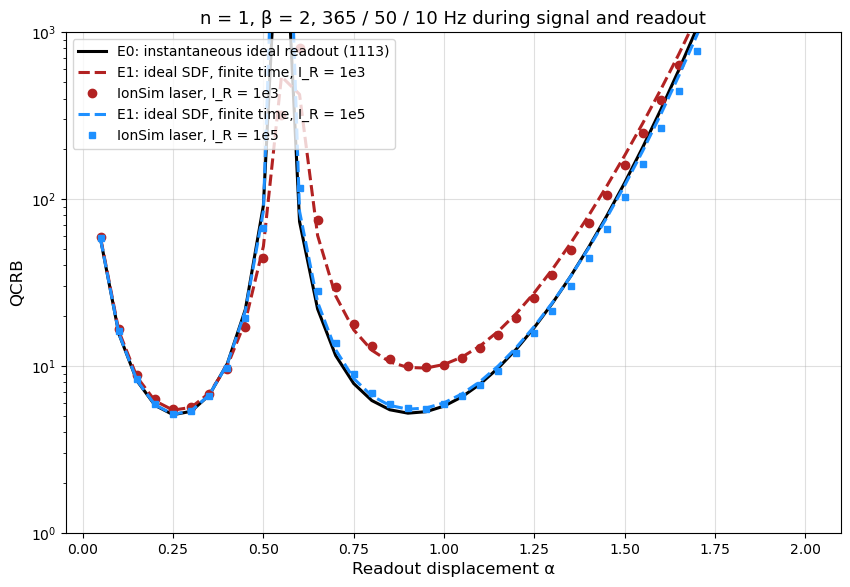

In [22]:
if haskey(results, ("1104 point", 1, 1e3))
    fig = figure(figsize=(10, 6.5))
    r1, r2 = results[("1104 point", 1, 1e3)], results[("1104 point", 1, 1e5)]
    plot(αs, r1.E0, "-", color="black", linewidth=2.2, label="E0: instantaneous ideal readout (1113)")
    plot(αs, r1.E1, "--", color="firebrick", linewidth=2.2, label="E1: ideal SDF, finite time, I_R = 1e3")
    plot(αs, r1.ion, "o", color="firebrick", markersize=6, label="IonSim laser, I_R = 1e3")
    plot(αs, r2.E1, "--", color="dodgerblue", linewidth=2.2, label="E1: ideal SDF, finite time, I_R = 1e5")
    plot(αs, r2.ion, "s", color="dodgerblue", markersize=5, label="IonSim laser, I_R = 1e5")
    yscale("log"); ylim(1, 1e3)
    xlabel("Readout displacement α", fontsize=12); ylabel("QCRB", fontsize=12)
    title("n = 1, β = 2, 365 / 50 / 10 Hz during signal and readout", fontsize=13)
    legend(fontsize=10, loc="upper left"); grid(alpha=0.4)
    display(fig); close(fig)
end

## 7. Carrier and counter-rotating terms (`rwa_cutoff = Inf`)

With `rwa_cutoff = 1e5` IonSim drops every term oscillating faster than 100 kHz, which removes the off-resonant carrier and counter-rotating terms. At the real Ω/ν ≈ 1.5e-3 a full run would integrate millions of trap periods, so this check raises the intensity until Ω/ν = 0.025 and compares `rwa_cutoff = Inf` (with `lamb_dicke_order = 2`) to `rwa_cutoff = 1e5` at the same intensity. The error from these terms grows with Ω/ν, so it is smaller still at the real intensity.

Noiseless n = 1, pure state, so kets are propagated instead of density matrices.

In [23]:
function qcrb_ionsim_pure(ψm, dψm, αs, I_R; rwa=1e5, ldo=1)
    h = hamiltonian(sdf_chamber(I_R; a=A_STAR), timescale=1e-6, rwa_cutoff=rwa, lamb_dicke_order=ldo)
    ts = vcat(0.0, collect(αs) ./ (G_SCALE * sdf_rate(I_R) * 1e-6))
    Ψ0 = ION["g"] ⊗ Ket(MODE, complex.(ψm)); dΨ0 = ION["g"] ⊗ Ket(MODE, complex.(dψm))
    _, Ψs = timeevolution.schroedinger_dynamic(ts, Ψ0, h; reltol=1e-10, abstol=1e-12)
    _, dΨs = timeevolution.schroedinger_dynamic(ts, dΨ0, h; reltol=1e-10, abstol=1e-12)
    return [qcrb_spin(Ψs[k] ⊗ dagger(Ψs[k]), dΨs[k] ⊗ dagger(Ψs[k]) + Ψs[k] ⊗ dagger(dΨs[k])) for k in 2:length(ts)]
end

ψm = displace_matrix(BETA)[:, 2]                       # D(β)|1⟩
Gm = diagm(1 => sqrt.(1:(DIM-1)))'; Gm = Gm - Gm'      # a† − a
dψm = Gm * ψm                                          # ∂β D(β)|1⟩ = (a† − a) D(β)|1⟩
I_fast = I_SIG * (0.025 * 2π * TRAP_FREQ / rabi(I_SIG))^2
q_rwa = @time qcrb_ionsim_pure(ψm, dψm, αs, I_fast; rwa=1e5, ldo=1)
q_inf = @time qcrb_ionsim_pure(ψm, dψm, αs, I_fast; rwa=Inf, ldo=2)
q_e0 = qcrb_E0(ψm * ψm', dψm * ψm' + ψm * dψm', αs)
win = q_e0 .<= 3minimum(q_e0)
@printf("Ω/ν = %.3f (I = %.3g):  min QCRB  E0 %.5g | IonSim RWA %.5g | IonSim no RWA %.5g\n",
        rabi(I_fast) / (2π * TRAP_FREQ), I_fast, minimum(q_e0), minimum(q_rwa), minimum(q_inf))
@printf("no RWA vs RWA: min shift %+.2e, max relative difference where QCRB < 3×min %.2e\n",
        minimum(q_inf) / minimum(q_rwa) - 1, maximum(abs.(q_inf .- q_rwa)[win] ./ q_rwa[win]))

  0.417197 seconds (3.56 M allocations: 125.356 MiB, 13.78% gc time, 54.20% compilation time)
 67.046461 seconds (892.98 M allocations: 32.978 GiB, 8.25% gc time, 0.22% compilation time)
Ω/ν = 0.025 (I = 2.68e+05):  min QCRB  E0 0.3758 | IonSim RWA 0.3752 | IonSim no RWA 0.37499
no RWA vs RWA: min shift -5.63e-04, max relative difference where QCRB < 3×min 3.54e-03


## 8. Verdict

Thresholds: the laser embedding is negligible if IonSim and E1 agree to within 3 % in min QCRB. The instantaneous readout is acceptable where E1/E0 − 1 stays below 5 %.

In [24]:
println("Laser embedding (IonSim vs E1, min QCRB):")
for (k, v) in sort(collect(results), by=x -> (x[1][1], x[1][2], x[1][3]))
    d = minimum(v.ion) / minimum(v.E1) - 1
    @printf("  %-11s n=%d I_R=%.0e  %+6.2f%%  %s\n", k[1], k[2], k[3], 100d, abs(d) <= 0.03 ? "ok" : "CHECK")
end
println("\nInstantaneous readout (E1 vs E0, min QCRB):")
for (k, v) in sort(collect(results), by=x -> (x[1][1], x[1][2], x[1][3]))
    k[1] == "noiseless" && continue
    d = minimum(v.E1) / minimum(v.E0) - 1
    @printf("  n=%d I_R=%.0e  %+7.2f%%  %s\n", k[2], k[3], 100d, d <= 0.05 ? "ok" : "readout noise matters")
end

Laser embedding (IonSim vs E1, min QCRB):
  1104 point  n=0 I_R=1e+03   +0.73%  ok
  1104 point  n=0 I_R=1e+05   +0.65%  ok
  1104 point  n=1 I_R=1e+03   +1.11%  ok
  1104 point  n=1 I_R=1e+05   +0.98%  ok
  1104 point  n=3 I_R=1e+03   +1.01%  ok
  1104 point  n=3 I_R=1e+05   -0.59%  ok
  noiseless   n=0 I_R=1e+03   -0.07%  ok
  noiseless   n=0 I_R=1e+05   -0.07%  ok
  noiseless   n=1 I_R=1e+03   -0.16%  ok
  noiseless   n=1 I_R=1e+05   -0.16%  ok
  noiseless   n=3 I_R=1e+03   -1.58%  ok
  noiseless   n=3 I_R=1e+05   -1.58%  ok

Instantaneous readout (E1 vs E0, min QCRB):
  n=0 I_R=1e+03   +12.15%  readout noise matters
  n=0 I_R=1e+05    +1.16%  ok
  n=1 I_R=1e+03    +6.54%  readout noise matters
  n=1 I_R=1e+05    +0.64%  ok
  n=3 I_R=1e+03   +27.05%  readout noise matters
  n=3 I_R=1e+05    +1.87%  ok
